In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import scienceplots
from scipy.integrate import odeint
from multiprocessing import Pool
from tqdm import tqdm
from scipy.io import loadmat
import pandas as pd
from scipy import integrate
from scipy.optimize import fsolve
import operator
import pickle
import hdf5storage
from itertools import permutations
import itertools
import random
import powerlaw
import networkx as nx
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
from pdf2image import convert_from_path
import matplotlib.pyplot as plt

In [2]:
data2 = loadmat('synthetic_structure_0116.mat')

In [3]:
A = data2['A']
degree_low = np.sum(A,1)

In [4]:
sis_data = loadmat('./sis/0116_matrix.mat')
regula_data = loadmat('./regula/0116_matrix.mat')
neuronal_data = loadmat('./neuronal/0116_matrix.mat')

In [5]:
x = []
B1 = data2['B1']
for i in range(len(B1)):
    degree_high = ([len(B1[i][j]) for j in range(len(B1[i]))])
    data = pd.DataFrame({"col1": degree_low, "col2": degree_high})
    result_df = data.groupby("col1", as_index=False)["col2"].mean()
    df = result_df[(result_df != 0).all(axis=1)]
    from scipy.stats import linregress
    log_x = np.log(df['col1'].tolist())
    log_y = np.log(df['col2'].tolist())

    slope, intercept, r_value, p_value, std_err = linregress(log_x, log_y)
    x.append(slope)

In [6]:
def round_nonzero(x):

    if np.isscalar(x):
        return 0 if (x == 0 and not isinstance(x, bool)) else x

    x = np.asarray(x)
    out = x.astype(object)
    zeros = (x == 0)  
    out[zeros] = 0  
    return out

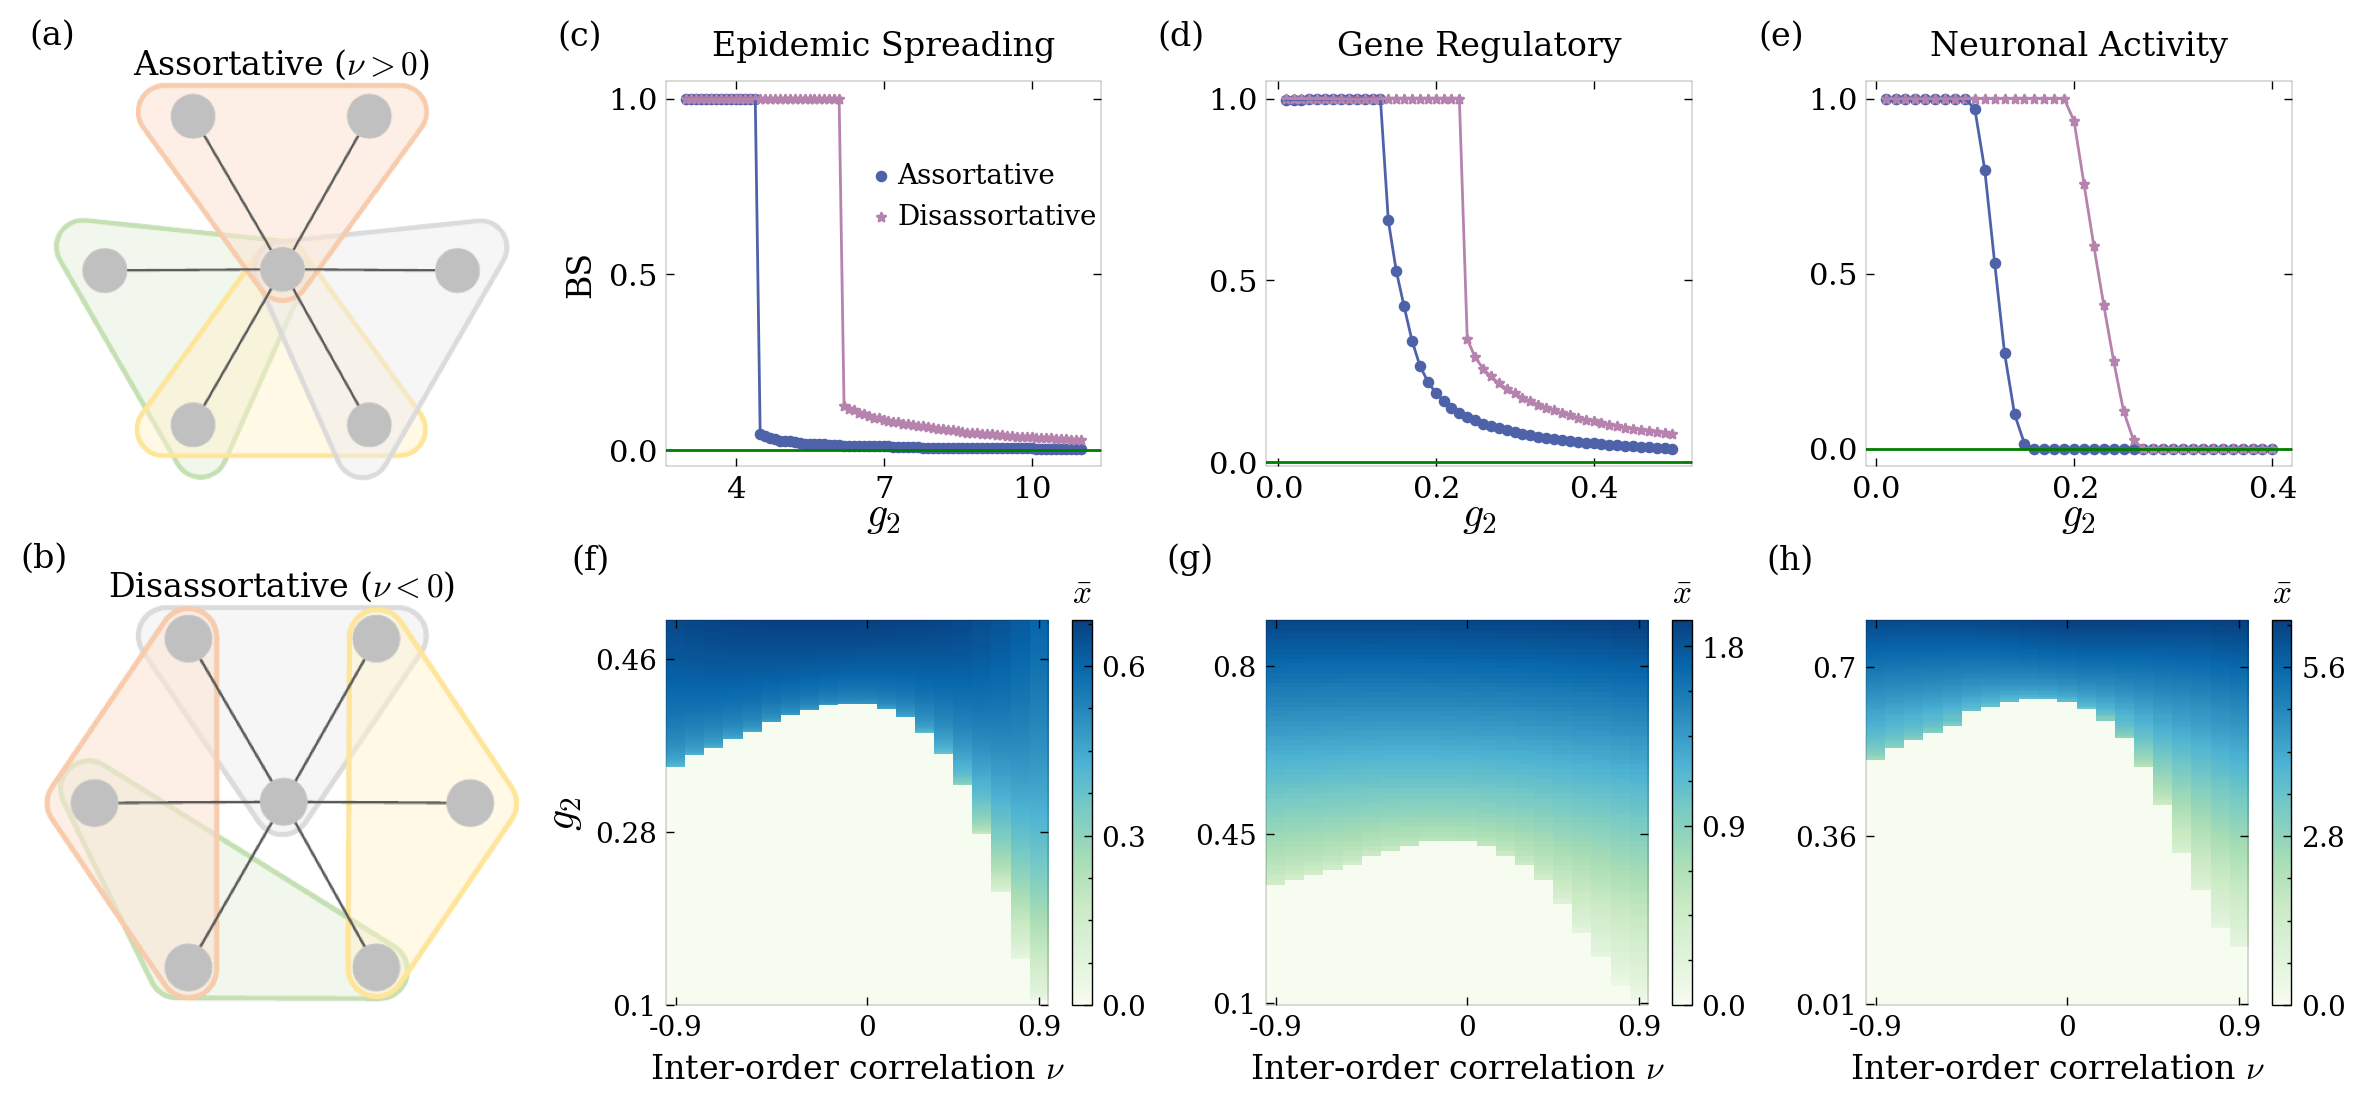

In [7]:
import matplotlib.pyplot as plt
from matplotlib import gridspec

fs1 = 15
fs = 12
bwith = 0.1
with plt.style.context(['science', 'no-latex']):
    fig = plt.figure(figsize=(15, 6))
    gs = gridspec.GridSpec(2, 4, figure=fig, width_ratios=[1.1, 1, 1, 1], height_ratios=[1, 1])
    left = gs[:, 0].subgridspec(2, 1, hspace=0.3)  

    ax1 = fig.add_subplot(left[0, 0])  
    ax11 = fig.add_subplot(left[1, 0])
    ax5 = fig.add_subplot(gs[1, 1])   
    ax6 = fig.add_subplot(gs[1, 2])   
    ax7 = fig.add_subplot(gs[1, 3])
    
    gs2 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[0, 1], width_ratios=[1,0])
    ax2 = fig.add_subplot(gs2[0])

    gs3 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[0, 2], width_ratios=[0.98,0.02])
    ax3 = fig.add_subplot(gs3[0])

    gs4 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[0, 3], width_ratios=[0.98,0.02])
    ax4 = fig.add_subplot(gs4[0])

    
    
    
    pdf_file = "assortative.pdf"
    pages = convert_from_path(pdf_file, first_page=1, last_page=1)  
    
   
    img = pages[0]
    ax1.imshow(img) #extent=[0, 22 * img.width, 0, 22 * img.height]
    ax1.axis('off')  
    box = ax1.get_position()  
    ax1.set_position([box.x0, box.y0 - 0.1, box.width, box.height])  



    pdf_file = "disassortative.pdf"
    pages = convert_from_path(pdf_file, first_page=1, last_page=1)  
    
    
    img = pages[0]
    ax11.imshow(img) #extent=[0, 22 * img.width, 0, 22 * img.height]
    ax11.axis('off')  
    box = ax11.get_position()  
    ax11.set_position([box.x0, box.y0 - 10, box.width, box.height])  
    

    ax = ax5
    color_matrix = sis_data['state_matrix']
    cax = ax.imshow(color_matrix, cmap='GnBu', interpolation='nearest', origin='lower',aspect='auto')

    cbar = ax.figure.colorbar(cax, ax=ax)
    cbar.ax.set_title(r'$\bar{x}$')
    ticks = [0, 0.3, 0.6]  
    cbar.set_ticks(ticks)

    
    x_ticks = np.arange(0, color_matrix.shape[1], 9)  
    x_ticks = [0,10,19]
    x_labels = [f'{round_nonzero(np.round(x[i],1))}' for i in x_ticks]
    ax.set_xticks(ticks=x_ticks,labels=x_labels)

    weight = sis_data['weight'][0] * 0.1
    y_ticks = np.arange(0, color_matrix.shape[0], 180)  
    
    y_labels = [f'{np.round(weight[i],2)}' for i in y_ticks]
    ax.set_yticks(ticks=y_ticks, labels=y_labels)
    ax.set_ylabel(r'$g_2$', fontsize=fs1)

    

     
    ### regula_high_order
    ax = ax6
    color_matrix = regula_data['state_matrix'][:80, :]
    cax = ax.imshow(color_matrix, cmap='GnBu', interpolation='nearest', origin='lower',aspect='auto')

    cbar = ax.figure.colorbar(cax, ax=ax)
    cbar.ax.set_title(r'$\bar{x}$')
    ticks = [0, 0.9, 1.8]  
    cbar.set_ticks(ticks)
    
    x_ticks = [0,10,19]  
    x_labels = [f'{round_nonzero(np.round(x[i],1))}' for i in x_ticks]
    ax.set_xticks(ticks=x_ticks, labels=x_labels)

    weight = regula_data['weight'][0]
    y_ticks = np.arange(0, color_matrix.shape[0], 35)  
    y_labels = [f'{np.round(weight[i],2)}' for i in y_ticks]
    ax.set_yticks(ticks=y_ticks, labels=y_labels)

    ### neuronal_high_order
    ax = ax7
    color_matrix = neuronal_data['state_matrix']
    cax = ax.imshow(color_matrix, cmap='GnBu', interpolation='nearest', origin='lower',aspect='auto')

    cbar = ax.figure.colorbar(cax, ax=ax)
    cbar.ax.set_title(r'$\bar{x}$')
    ticks = [0, 2.8, 5.6]  
    cbar.set_ticks(ticks)

    x_ticks = [0,10,19]  
    x_labels = [f'{round_nonzero(np.round(x[i],1))}' for i in x_ticks]
    ax.set_xticks(ticks=x_ticks, labels=x_labels)

    weight = neuronal_data['weight'][0]
    y_ticks = np.arange(0, color_matrix.shape[0], 70)  
    y_labels = [f'{np.round(weight[i],2)}' for i in y_ticks]
    ax.set_yticks(ticks=y_ticks, labels=y_labels)

    axs = [ax5, ax6, ax7]
    for ax in axs:
        ax.set_xlabel('Inter-order correlation '+r'$\nu$', fontsize=fs)
        ax.spines['bottom'].set_linewidth(bwith)
        ax.spines['left'].set_linewidth(bwith)
        ax.spines['top'].set_linewidth(bwith)
        ax.spines['right'].set_linewidth(bwith)
        # ax.tick_params(axis='x', labelsize=fs-1, pad=10)
        # ax.tick_params(axis='y', labelsize=fs-1)
        ax.xaxis.set_minor_locator(plt.NullLocator())  
        ax.yaxis.set_minor_locator(plt.NullLocator())  
        # ticks = [-0.9, 0, 0.8]  
        # ax.set_xticks(ticks)

    
    bs_weight_ = hdf5storage.loadmat('./sis/three_hoi_structure_0804.mat')
    bs_weight1 = bs_weight_['bs_weight1']
    bs_weight2 = bs_weight_['bs_weight2']
    bs_weight3 = bs_weight_['bs_weight3']
    ax = ax2
    ax.scatter(bs_weight1[:,0],bs_weight1[:,1],label='Assortative',color=(78/256,98/256,171/256), s=10)
    ax.plot(bs_weight1[:,0],bs_weight1[:,1], color=(78/256,98/256,171/256), linestyle='-', linewidth=1)
    ax.scatter(bs_weight2[:,0],bs_weight2[:,1],marker='*',label='Disassortative',color=(183/256,131/256,175/256 ), s=10)
    ax.plot(bs_weight2[:,0],bs_weight2[:,1], color=(183/256,131/256,175/256 ), linestyle='-', linewidth=1)
    
    ax.text(0.5, 1.05, 'Epidemic Spreading', fontsize=fs,  ha='center', va='bottom', transform=ax.transAxes)
    ax.set_ylabel('BS', fontsize=fs)
    ax.legend(loc='center', bbox_to_anchor=(0.71, 0.7), fontsize=10, handletextpad=-0.4)
    ticks = [4, 7, 10]  
    ax.set_xticks(ticks)
    
    bs_weight_ = hdf5storage.loadmat('./regula/three_hoi_structure_0804.mat')
    bs_weight1 = bs_weight_['bs_weight1']
    bs_weight2 = bs_weight_['bs_weight2']
    bs_weight3 = bs_weight_['bs_weight3']
    ax = ax3
    ax.scatter(bs_weight1[:,0],bs_weight1[:,1],label='Positive',color=(78/256,98/256,171/256), s=10)
    ax.plot(bs_weight1[:,0],bs_weight1[:,1], color=(78/256,98/256,171/256), linestyle='-', linewidth=1)
    ax.scatter(bs_weight2[:,0],bs_weight2[:,1],label='Positive',marker='*',color=(183/256,131/256,175/256 ), s=10)
    ax.plot(bs_weight2[:,0],bs_weight2[:,1], color=(183/256,131/256,175/256 ), linestyle='-', linewidth=1)
    ax.text(0.5, 1.05, 'Gene Regulatory', fontsize=fs,  ha='center', va='bottom', transform=ax.transAxes)

    bs_weight_ = hdf5storage.loadmat('./neuronal/three_hoi_structure_0804.mat')
    bs_weight1 = bs_weight_['bs_weight1']
    bs_weight2 = bs_weight_['bs_weight2']
    bs_weight3 = bs_weight_['bs_weight3']
    ax = ax4
    ax.scatter(bs_weight1[:,0],bs_weight1[:,1],label='Positive',color=(78/256,98/256,171/256), s=10)
    ax.plot(bs_weight1[:,0],bs_weight1[:,1], color=(78/256,98/256,171/256), linestyle='-', linewidth=1)
    ax.scatter(bs_weight2[:,0],bs_weight2[:,1],label=-1,marker='*',color=(183/256,131/256,175/256 ), s=10)
    ax.plot(bs_weight2[:,0],bs_weight2[:,1], color=(183/256,131/256,175/256 ), linestyle='-', linewidth=1)
    ax.text(0.5, 1.05, 'Neuronal Activity', fontsize=fs,  ha='center', va='bottom', transform=ax.transAxes)
    
    axs = [ax2, ax3, ax4]
    for ax in axs:
        ax.axhline(0, color ='green', lw = 1)
        ax.set_xlabel(r'$g_2$', fontsize=fs1, labelpad=-3)
        ax.spines['bottom'].set_linewidth(bwith)
        ax.spines['left'].set_linewidth(bwith)
        ax.spines['top'].set_linewidth(bwith)
        ax.spines['right'].set_linewidth(bwith)
        ax.tick_params(axis='x', labelsize=fs-1)
        ax.tick_params(axis='y', labelsize=fs-1)
        ax.xaxis.set_minor_locator(plt.NullLocator())  
        ax.yaxis.set_minor_locator(plt.NullLocator())  
        ticks = [0, 0.5, 1]  
        ax.set_yticks(ticks)

        

    ax1.set_title('(a)',x=0, y=1.05,fontsize=fs)
    ax1.text(0.5, 1, 'Assortative'+' '+r'($\nu>0$)', fontsize=fs,  ha='center', va='bottom', transform=ax1.transAxes)
    ax11.set_title('(b)',x=0, y=1.05,fontsize=fs)
    ax11.text(0.5, 1, 'Disassortative'+' '+r'($\nu<0$)', fontsize=fs,  ha='center', va='bottom', transform=ax11.transAxes)
    
    ax2.set_title('(c)',x=-0.2, y=1.05, fontsize = fs)
    ax3.set_title('(d)',x=-0.2, y=1.05, fontsize = fs)
    ax4.set_title('(e)',x=-0.2, y=1.05, fontsize = fs)

    ax5.set_title('(f)',x=-0.2, y=1.09, fontsize = fs)
    ax6.set_title('(g)',x=-0.2, y=1.09, fontsize = fs)
    ax7.set_title('(h)',x=-0.2, y=1.09, fontsize = fs)
        
    gs.update(hspace=0.4, wspace=0.25)

plt.savefig("Fig4_0523.pdf", format='pdf', bbox_inches='tight',dpi=300,pad_inches=0.0)
plt.show()